# 04 · Training: configuring and running `anemoi-training`

**AIWCAS 2026 · Anemoi hands-on · about 15 minutes**

Notebooks 01–03 gave you the three ingredients: a **dataset** (01), a **graph** (02) and a **model** (03).
`anemoi-training` puts them together and runs the optimisation loop. Almost everything you control goes
through **one configuration**, so this notebook is about reading and writing that configuration, and about
what happens when you call `anemoi-training train`.

After it you should be able to

- read an anemoi-training config, override parts of it, and validate it;
- say what one training sample contains (inputs, targets, rollout) and how it is weighted in the loss;
- know which knobs control the run (variables, dates, model size, rollout, learning rate, hardware) and where outputs go.

| § | Topic | Minutes |
|---|-------|---------|
| 1 | The config system: Hydra groups, overrides, validation | 5 |
| 2 | From config to batches: datamodule and task | 3 |
| 3 | The loss and its weights | 3 |
| 4 | Optimiser, rollout, checkpoints, logging, Slurm | 2 |
| 5 | A few training steps on the CPU, and a reference GPU run | 2 |
| 6 | Try it (two short exercises) | in hour 2 |

> **Login node etiquette.** Everything here runs on the CPU of the shared login node with a tiny model and
> at most 8 threads. The first import of the Anemoi stack from the Lustre file system is slow (one to three minutes);
> the cells after that are quick.

*Version: anemoi-training 0.17.1 (anemoi-core tag `training-0.17.1`), anemoi-models 0.19, anemoi-graphs 0.9.8.*

In [1]:
import os, time, logging, warnings
from pathlib import Path

T0 = time.time()
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CONFIG_DIR = REPO / "configs"                      # our tiny config lives here
SCRATCH = Path(os.environ["SCRATCH"])
OUT = SCRATCH / "aiwcas26" / "training" / "notebook04"   # outputs of this notebook
DATA = Path("/leonardo_work/tra26_aiwcas/a08trd25/data")   # read-only tutorial data

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"     # MLflow >= 3 refuses its ./mlruns file store otherwise
os.environ["OMP_NUM_THREADS"] = "8"                # be gentle with the shared login node
warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.WARNING)

import numpy as np
import matplotlib.pyplot as plt
import torch
torch.set_num_threads(8)

# A small, consistent plotting style for this notebook
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlecolor": INK,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
})
print(f"repo: {REPO}\nconfigs: {CONFIG_DIR}\noutputs: {OUT}\nsetup took {time.time() - T0:.0f} s")

repo: /leonardo/home/usertrain/a08trd25/aiwcas26-anemoi-tutorial
configs: /leonardo/home/usertrain/a08trd25/aiwcas26-anemoi-tutorial/configs
outputs: /leonardo_scratch/large/usertrain/a08trd25/aiwcas26/training/notebook04
setup took 74 s


## 1 · The config system (5 min)

`anemoi-training` is configured with [Hydra](https://hydra.cc). A Hydra config is a tree of YAML files organised
in **config groups** (directories). Each group has several **options** (files), and a top-level file picks one
option per group in its `defaults:` list. Your own file then overrides individual values, and the command line
overrides those again.

![Config composition](figures/04_config_composition.svg)

**Why Hydra?**

- *Composable experiments*: swap a whole component with one word (`model=transformer`, `graph=encoder_decoder_only`)
  instead of editing a 500-line file.
- *Overrides and sweeps*: any value can be changed from the command line (`training.max_steps=50`), so a
  learning-rate sweep is a loop over a command, not a set of copied files.
- *Reproducibility*: the fully composed config is logged with each run and stored **inside every checkpoint**.

These are the groups and options that ship with this version:

In [2]:
import importlib.resources as ir

cfg_root = ir.files("anemoi.training") / "config"
for group in sorted(p for p in cfg_root.iterdir() if p.is_dir() and not p.name.startswith("_")):
    options = sorted(f.stem for f in group.iterdir() if f.suffix == ".yaml")
    subgroups = sorted(d.name for d in group.iterdir() if d.is_dir() and not d.name.startswith("_"))
    line = f"{group.name:<12} options: {', '.join(options) or '-'}"
    if subgroups:
        line += f"\n{'':<12} sub-groups: {', '.join(subgroups)}"
    print(line)

data         options: multi, zarr
dataloader   options: forecast_native_grid, multi, native_grid
diagnostics  options: evaluation, evaluation_ens, evaluation_multi
             sub-groups: benchmark_profiler, callbacks, log, plot
graph        options: encoder_decoder_only, existing, hierarchical_2level, hierarchical_2level_encoder_decoder_only, hierarchical_3level, limited_area, multi, multi_scale, point_wise, stretched_grid
model        options: gnn, graphtransformer, graphtransformer_ens, graphtransformer_multi, graphtransformer_multi_transport, graphtransformer_multi_transport_edm, graphtransformer_multi_transport_si, graphtransformer_multi_transport_tendency, graphtransformer_multi_transport_tendency_edm, graphtransformer_transport, graphtransformer_transport_edm, graphtransformer_transport_si, graphtransformer_transport_tendency, graphtransformer_transport_tendency_edm, graphtransformer_transport_tendency_si, point_wise, transformer, transformer_ens, transformer_transformermapper,

The packaged `config.yaml` uses `data: zarr, dataloader: native_grid, diagnostics: evaluation, system: example,
graph: multi_scale, model: gnn, task: forecaster, training: single`. Its required paths are `???` (Hydra's
"missing value"), so it cannot run until you fill them in. `anemoi-training config generate -o my_configs/`
copies all these YAML files to a directory so you can read and edit them.

Our tiny config keeps those defaults and overrides only what we need: data paths, dates, a small model, a short
run and offline logging. Read it once; this is the file you will adapt in the second hour.

In [3]:
print((CONFIG_DIR / "04_tiny_train.yaml").read_text())

# =============================================================================
# AIWCAS 2026 Anemoi tutorial -- a *tiny* anemoi-training config (training-0.17.1)
#
# Trains a small GNN encoder-processor-decoder on the 10-day O96 ERA5 sample
# dataset on ONE GPU, in a few minutes, so you can watch the loss go down.
# It is NOT meant to produce a useful forecast model.
#
#   anemoi-training config validate --config-path configs --config-name 04_tiny_train
#   anemoi-training train            --config-path configs --config-name 04_tiny_train
#   # (or: sbatch scripts/train_tiny.sbatch)
#
# Everything not set here comes from the packaged defaults listed below; see
#   anemoi-training config generate -o my_configs/   (copies every default yaml)
# Command-line overrides win over this file, e.g.
#   anemoi-training train --config-name 04_tiny_train training.max_steps=50 model.num_channels=32
# =============================================================================
defaults:
  - data: z

### Composing the config from Python

`anemoi-training train` does this composition for you. The Hydra **compose API** does the same in a notebook.
The packaged defaults are found through Anemoi's Hydra search-path plugin, so we only point Hydra at our own
config directory.

In [4]:
from hydra import compose, initialize_config_dir
from omegaconf import OmegaConf

def compose_cfg(overrides=(), name="04_tiny_train"):
    with initialize_config_dir(version_base=None, config_dir=str(CONFIG_DIR)):
        return compose(config_name=name, overrides=list(overrides))

cfg = compose_cfg()

def show_tree(node, depth=2, indent=""):
    # Print the top of a config tree, with the number of leaf values below each branch
    for key, value in node.items():
        if OmegaConf.is_dict(value):
            n_leaves = len(OmegaConf.to_container(value, resolve=False)) if depth <= 1 else None
            print(f"{indent}{key}/" + (f"  ({n_leaves} keys)" if n_leaves is not None else ""))
            if depth > 1:
                show_tree(value, depth - 1, indent + "    ")
        else:
            text = OmegaConf.to_yaml({key: value}).strip() if OmegaConf.is_list(value) else f"{key}: {value}"
            print(indent + text.replace("\n", " ")[:90])

show_tree(cfg, depth=2)

data/
    format: zarr
    frequency: 6h
    datasets/  (1 keys)
dataloader/
    prefetch_factor: 2
    pin_memory: True
    persistent_workers: True
    read_group_size: 1
    num_workers/  (3 keys)
    batch_size/  (3 keys)
    limit_batches/  (3 keys)
    dataset: /leonardo_work/tra26_aiwcas/a08trd25/data/anemoi/aifs-ea-an-oper-0001-mars-o96-20
    training/  (1 keys)
    validation/  (1 keys)
    test/  (1 keys)
diagnostics/
    plot/  (7 keys)
    callbacks: []
    benchmark_profiler/  (6 keys)
    log/  (2 keys)
    debug/  (1 keys)
    enable_checkpointing: True
    checkpoint/  (3 keys)
    enable_progress_bar: True
    progress_bar/  (2 keys)
    check_val_every_n_epoch: 1
    print_memory_summary: False
system/
    output/  (5 keys)
    input/  (6 keys)
    hardware/  (4 keys)
graph/
    overwrite: False
    nodes/  (2 keys)
    edges: - source_name: data   target_name: hidden   edge_builders:   - _target_: anemoi.gra
    attributes/  (2 keys)
    post_processors: []
model/
 

Values like `${dataloader.dataset}` are **interpolations**: they point at another key and are resolved when the
config is used. This is how one path in `system.input.dataset` reaches the training, validation and test
dataloaders and the graph builder. Here is the dataset spec of the training split, before and after resolving:

In [5]:
spec = cfg.dataloader.training.datasets.data
print("raw:      ", OmegaConf.to_container(spec, resolve=False))
print("resolved: ", OmegaConf.to_container(spec, resolve=True))

raw:       {'dataset_config': {'dataset': '${dataloader.dataset}', 'frequency': '${data.frequency}'}, 'start': '2017-01-01', 'end': '2017-01-08'}
resolved:  {'dataset_config': {'dataset': '/leonardo_work/tra26_aiwcas/a08trd25/data/anemoi/aifs-ea-an-oper-0001-mars-o96-2017-2017-6h-v8-testing.zarr', 'frequency': '6h'}, 'start': '2017-01-01', 'end': '2017-01-08'}


The `dataset_config` dictionary is handed **unchanged** to `anemoi.datasets.open_dataset`, together with the
`start`/`end` of the split (see `anemoi/training/data/data_reader.py`). So every option you met in notebook 01
(`select`, `drop`, `frequency`, `area`, `thinning`, joins, ...) can be written straight into the training config.
Let us open exactly what the training split will see:

In [6]:
from anemoi.datasets import open_dataset

resolved = OmegaConf.to_container(spec, resolve=True)
ds_train = open_dataset(resolved["dataset_config"], start=resolved["start"], end=resolved["end"])
print(f"training split: {ds_train.shape}  (dates, variables, ensemble, grid points)")
print(f"dates: {ds_train.dates[0]} .. {ds_train.dates[-1]}  every {ds_train.frequency}")
vs = OmegaConf.to_container(cfg.dataloader.validation.datasets.data, resolve=True)
ds_val = open_dataset(vs["dataset_config"], start=vs["start"], end=vs["end"])
print(f"validation split: {ds_val.dates[0]} .. {ds_val.dates[-1]}  ({len(ds_val.dates)} dates)")

training split: (31, 101, 1, 40320)  (dates, variables, ensemble, grid points)
dates: 2017-01-01T06:00:00 .. 2017-01-08T18:00:00  every 6:00:00
validation split: 2017-01-09T00:00:00 .. 2017-01-10T18:00:00  (8 dates)


### Overrides

On the command line an override is `key=value` (change), `+key=value` (add a key that does not exist yet),
`~key` (delete), and `group=option` (swap a whole group). The compose API takes the same strings:

In [7]:
over = ["model.num_channels=32", "task.rollout.maximum=3", "training.optimization.lr=5e-4", "graph=encoder_decoder_only"]
cfg2 = compose_cfg(over)
for key in ["model.num_channels", "task.rollout.maximum", "training.optimization.lr", "graph.nodes.hidden.node_builder._target_"]:
    print(f"{key:<42} {str(OmegaConf.select(cfg, key)):<38} -> {OmegaConf.select(cfg2, key)}")

model.num_channels                         64                                     -> 32
task.rollout.maximum                       1                                      -> 3
training.optimization.lr                   0.001                                  -> 0.0005
graph.nodes.hidden.node_builder._target_   anemoi.graphs.nodes.TriNodes           -> anemoi.graphs.nodes.ReducedGaussianGridNodes


### Validation with pydantic

At startup the trainer resolves the config and validates it against a **pydantic schema**
(`anemoi.training.schemas.base_schema.BaseSchema`, switched on by `config_validation: True`). Types are checked,
required fields must be present and unknown keys are rejected in most sections. You get the error in seconds
instead of after the job has waited in the queue. Two typical mistakes:

In [8]:
from anemoi.training.schemas.base_schema import BaseSchema

def validate(c):
    c = c.copy()
    OmegaConf.resolve(c)
    return BaseSchema(**c)

schema = validate(cfg)
print("valid ✓   training method:", type(schema.training).__name__, "| task:", type(schema.task).__name__)

# 1) A wrong type: Lightning precision must be a string such as "32-true" or "16-mixed"
try:
    validate(compose_cfg(["training.precision=32"]))
except Exception as err:
    print("\n✗ pydantic:", str(err).splitlines()[0], "\n ", "\n  ".join(str(err).splitlines()[1:3]))

# 2) A typo in a key: Hydra itself refuses to override a key that does not exist
try:
    compose_cfg(["training.max_step=10"])
except Exception as err:
    print("\n✗ hydra:", str(err).splitlines()[0])

valid ✓   training method: SingleTrainingSchema | task: ForecasterSchema



✗ pydantic: 1 validation error for BaseSchema 
  training.`anemoi.training.train.methods.SingleTraining`.precision
    Input should be a valid string [type=string_type, input_value=32, input_type=int]



✗ hydra: Could not override 'training.max_step'.


The same tools exist on the command line (run from the repository root):

```bash
anemoi-training config generate -o my_configs/                         # copy all packaged defaults
anemoi-training config validate --config-path configs --config-name 04_tiny_train
anemoi-training config dump     --config-path configs --config-name 04_tiny_train -o composed.yaml
anemoi-training train --config-path $PWD/configs --config-name 04_tiny_train training.max_steps=50
```

> ⚠️ For `train`, `--config-path` must be an **absolute** path (Hydra resolves relative paths against the
> Python package, not your shell). `config validate` accepts relative paths.

## 2 · What happens when you call `anemoi-training train` (3 min)

`anemoi-training train` builds an `AnemoiTrainer` from the composed config, which, in order:

1. **validates** the config (§1) and sets up output paths under `system.output.root` with a unique run id;
2. builds the **task** (`task: forecaster`): which time offsets are inputs and which are targets;
3. builds the **datamodule** (`AnemoiDatasetsDataModule`): one `open_dataset` per split, sliced into samples;
4. loads the **graph** from `system.input.graph`, or builds it from the `graph:` section and saves it there;
5. builds the **Lightning module** (`training.method`, here `SingleTraining` for a deterministic model): the
   `AnemoiModelInterface` of notebook 03 (pre-processors + model) together with the loss, scalers and optimiser;
6. creates a `pytorch_lightning.Trainer` (devices, precision, callbacks, logger) and calls `trainer.fit`.

We do steps 1–5 here, on the CPU, with a few overrides that keep it light. One of them swaps the default
`DDPGroupStrategy` (data-parallel, also used for a single GPU) for anemoi's `SingleDeviceStrategy`, because Lightning
does not allow DDP strategies in an interactive Jupyter session:

In [9]:
from anemoi.training.train.train import AnemoiTrainer

CPU_OVERRIDES = [
    "system.hardware.accelerator=cpu", "training.precision=32-true",   # no GPU on the login node
    # Lightning refuses DDP strategies inside Jupyter; anemoi ships a single-device strategy for this case
    "training.strategy._target_=anemoi.training.distributed.single.SingleDeviceStrategy",
    f"system.output.root={OUT}",
    "dataloader.num_workers.training=2", "dataloader.num_workers.validation=1",
    "dataloader.limit_batches.validation=2",
    "training.max_steps=12", "training.optimization.lr_scheduler.warmup_t=2",
    "diagnostics.log.interval=1", "diagnostics.progress_bar.refresh_rate=4",
]
t = time.time()
cfg_cpu = compose_cfg(CPU_OVERRIDES)
trainer = AnemoiTrainer(cfg_cpu)          # validates the config, prepares paths and the MLflow (offline) logger
dm = trainer.datamodule                   # AnemoiDatasetsDataModule
task = trainer.task                       # Forecaster
print(f"trainer ready in {time.time() - t:.0f} s;  run id {trainer.run_id}")
hours = lambda offsets: [f"{o.total_seconds() / 3600:+.0f}h" for o in offsets]
print("task offsets:", hours(task.get_offsets(mode="training")),
      "| inputs at", task.get_batch_input_indices(), "| target at", task.get_batch_output_indices())

2026/10/24 12:59:59 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /leonardo_scratch/large/usertrain/a08trd25/envs/anemoi/lib/python3.11/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


trainer ready in 17 s;  run id d2699711a1114b9ea47a0ea9e5b7448f
task offsets: ['-6h', '+0h', '+6h'] | inputs at [0, 1] | target at [2]


### One training sample

The forecaster with `multistep_input: 2` and `timestep: 6H` uses the offsets −6 h and 0 h as input and +6 h as the
target, so each sample loads **three consecutive dates**. With a rollout of *R* steps it loads 2 + *R* dates.

![Training sample timeline](figures/04_training_sample_timeline.svg)

The training dataset is an iterable over *anchors* (valid start positions). Let us fetch one sample directly:

In [10]:
ds = dm.ds_train                       # MultiDataset, one reader per dataset name ("data")
reader = ds.data_readers["data"]
print(f"{len(ds.anchors)} training samples (anchors) in {len(reader.dates)} dates")

sample = ds.get_sample(0)["data"]      # what the dataloader yields, before batching
print("sample shape:", tuple(sample.shape), " = (time, ensemble, grid points, variables)")

position = int(ds.anchors[0][1])
dates = reader.dates[position - 1: position + 2]
roles = ["input  (t-6h)", "input  (t)", "target (t+6h)"]
for k, (d, r) in enumerate(zip(dates, roles)):
    print(f"  batch[:, {k}]  {str(d)[:16]}  {r}")

idx = dm.data_indices["data"]
names = list(reader.variables)
print(f"\n{len(idx.data.input.forcing)} forcings (input only):   ", [names[i] for i in idx.data.input.forcing][:6], "...")
print(f"{len(idx.data.output.diagnostic)} diagnostics (output only):", [names[i] for i in idx.data.output.diagnostic])
print(f"{len(idx.data.input.prognostic)} prognostic variables (input and output)")

29 training samples (anchors) in 31 dates


sample shape: (3, 1, 40320, 101)  = (time, ensemble, grid points, variables)
  batch[:, 0]  2017-01-01T06:00  input  (t-6h)
  batch[:, 1]  2017-01-01T12:00  input  (t)
  batch[:, 2]  2017-01-01T18:00  target (t+6h)



13 forcings (input only):    ['cos_julian_day', 'cos_latitude', 'cos_local_time', 'cos_longitude', 'insolation', 'lsm'] ...
2 diagnostics (output only): ['cp', 'tp']
86 prognostic variables (input and output)


The sample is in **physical units**: normalisation (the pre-processors of notebook 03) runs inside the model
interface, on the GPU. After batching, the trainer sees `(batch, time, ensemble, grid, variables)`. Here is one
variable at the three dates of the sample:

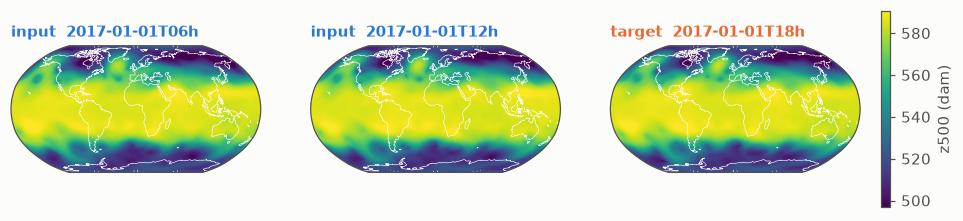

In [11]:
import cartopy, cartopy.crs as ccrs
cartopy.config["data_dir"] = str(DATA / "cartopy")   # offline Natural Earth coastlines

lat, lon = reader.data.latitudes, reader.data.longitudes
var = "z_500"
field = sample[:, 0, :, reader.name_to_index[var]].numpy() / 9.80665 / 10   # geopotential -> dam
vmin, vmax = np.percentile(field, [1, 99])
fig, axes = plt.subplots(1, 3, figsize=(12, 2.9), subplot_kw={"projection": ccrs.Robinson()})
for k, ax in enumerate(axes):
    sc = ax.scatter(lon, lat, c=field[k], s=0.4, cmap="viridis", vmin=vmin, vmax=vmax,
                    transform=ccrs.PlateCarree(), rasterized=True)
    ax.coastlines(lw=0.4, color="white")
    ax.set_global()
    ax.set_title(f"{roles[k].split()[0]}  {str(dates[k])[:13]}h", fontsize=10,
                 color=SERIES[0] if k < 2 else SERIES[1])
cb = fig.colorbar(sc, ax=axes, shrink=0.8, pad=0.02)
cb.set_label("z500 (dam)")
plt.show()

## 3 · The loss and its weights (3 min)

The default training loss is a **weighted mean squared error** in normalised space:

$$
\mathcal{L} \;=\; \frac{1}{R}\sum_{r=1}^{R}\; \sum_{i\,\in\,\text{grid}} \; \sum_{v\,\in\,\text{vars}}
\; w_i\, s_v \,\big(\hat y_{r,i,v} - y_{r,i,v}\big)^2
$$

- $w_i$ = **node weights** (`node_weights` scaler): the `area_weight` attribute of the data nodes of the graph
  (notebook 02), normalised to sum to one. On a reduced Gaussian grid the points are not equal-area, so without
  it the loss would over-count some latitudes.
- $s_v$ = **variable weights**: `general_variable` (one weight per variable or parameter, e.g. `z: 12`, `tp: 0.025`)
  times `pressure_level` (a ramp that down-weights the upper levels). After normalisation every variable has a
  similar scale, so these weights are how you say *what you care about*: a variable with weight 0 is still predicted,
  but nothing pushes it to be right.
- $R$ = rollout length (§4).

Which scalers enter the loss is a list in `training.training_loss.datasets.data.scalers`; their definitions live in
`training.scalers`. Building the Lightning module creates them (this takes about 30 s on the login node):

In [12]:
t = time.time()
module = trainer.model                    # SingleTraining (a LightningModule)
print(f"model built in {time.time() - t:.0f} s: {sum(p.numel() for p in module.parameters()) / 1e6:.1f} M parameters")
print("loss:", type(module.loss["data"].loss).__name__, "| scalers in the loss:", list(module.loss["data"].scaler))
for name, (dims, tensor) in module.scalers["data"].items():
    print(f"  {name:<18} acts on dims {dims}, shape {tuple(tensor.shape)}")

Seed set to 2684470948


No timestep provided for tendency scaler, defaulting to first lead time: '6h'.


No timestep provided for tendency scaler, defaulting to first lead time: '6h'.


model built in 47 s: 2.3 M parameters
loss: MSELoss | scalers in the loss: ['pressure_level', 'general_variable', 'node_weights', 'time_steps']
  general_variable   acts on dims (4,), shape (88,)
  pressure_level     acts on dims (4,), shape (88,)
  nan_mask_weights   acts on dims (0, 3, 4), shape (1, 1, 1)
  stdev_tendency     acts on dims (4,), shape (88,)
  var_tendency       acts on dims (4,), shape (88,)
  node_weights       acts on dims (3,), shape (40320,)
  time_steps         acts on dims (1,), shape (1,)


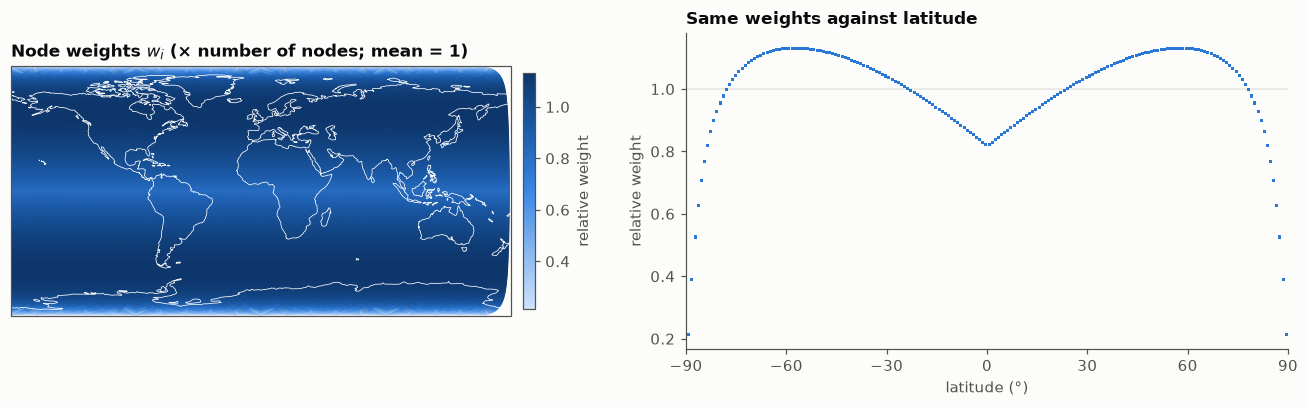

min/max weight ratio: 0.19


In [13]:
from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

graph = trainer.graph_data
glat, glon = np.rad2deg(graph["data"].x[:, 0].numpy()), np.rad2deg(graph["data"].x[:, 1].numpy())
area = graph["data"]["area_weight"].squeeze().numpy()           # graph attribute (unit-max)
w = module.scalers["data"]["node_weights"][1].numpy()           # as used in the loss (unit-sum)

import matplotlib.tri as mtri
fig = plt.figure(figsize=(12, 3.8))
ax = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
lon180 = (glon + 180) % 360 - 180
sc = ax.tripcolor(mtri.Triangulation(lon180, glat), w * len(w), cmap=blues, shading="gouraud", rasterized=True)
ax.coastlines(lw=0.5, color="white"); ax.set_global()
ax.set_title("Node weights $w_i$ (× number of nodes; mean = 1)")
fig.colorbar(sc, ax=ax, shrink=0.75, pad=0.02, label="relative weight")

ax2 = fig.add_subplot(1, 2, 2)
order = np.argsort(glat)
ax2.plot(glat[order], (w * len(w))[order], ".", ms=1.5, color=SERIES[0], rasterized=True)
ax2.axhline(1, color=GRID, lw=1, zorder=0)
ax2.set_xlabel("latitude (°)"); ax2.set_ylabel("relative weight")
ax2.set_title("Same weights against latitude")
ax2.set_xlim(-90, 90); ax2.set_xticks(range(-90, 91, 30))
fig.tight_layout(); plt.show()
print(f"min/max weight ratio: {w.min() / w.max():.2f}")

The weights depend only on latitude. The octahedral O96 grid is designed to be roughly uniform, but not exactly:
the equator ring holds the most points (each covers a little less area, weight ≈ 0.8), the rings near ±60° the
largest areas (≈ 1.13), and the few points right next to the poles cover tiny areas (≈ 0.2). On a regular lat–lon
grid (notebook 01's WeatherBench2 example) the polar weights would fall almost to zero. Either way, the weighting
makes the loss an approximation of the **area integral** over the globe instead of a sum that favours wherever the
grid happens to be dense.

Now the variable weights, the product of `general_variable` and `pressure_level`, as the trainer prints them at
startup:

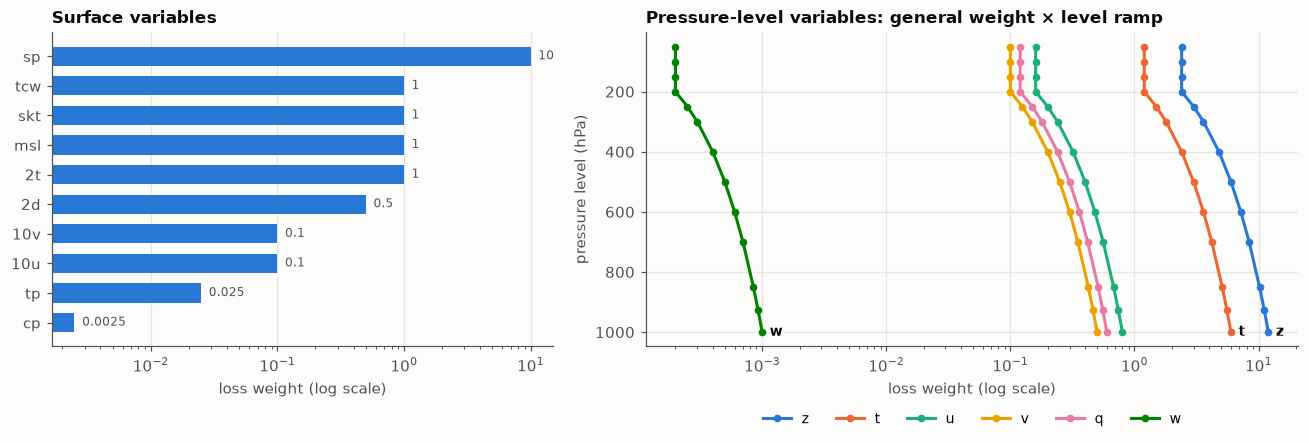

In [14]:
scaling = module._scaling_values_log["data"]          # {variable: combined weight}
levels = [50, 100, 150, 200, 250, 300, 400, 500, 600, 700, 850, 925, 1000]
params = ["z", "t", "u", "v", "q", "w"]
surface = {k: v for k, v in scaling.items() if "_" not in k}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
names_s = sorted(surface, key=surface.get)
ax1.barh(names_s, [surface[n] for n in names_s], color=SERIES[0], height=0.65)
ax1.set_xscale("log"); ax1.set_xlabel("loss weight (log scale)")
ax1.set_title("Surface variables")
for y, n in enumerate(names_s):
    ax1.text(surface[n] * 1.15, y, f"{surface[n]:g}", va="center", fontsize=8, color=INK2)
ax1.grid(axis="x", color=GRID, lw=0.8); ax1.set_axisbelow(True)

for k, p in enumerate(params):
    vals = [scaling[f"{p}_{l}"] for l in levels]
    ax2.plot(vals, levels, marker="o", ms=4, lw=2, color=SERIES[k], label=p)
    if p in ("z", "t", "w"):                         # direct labels where the lines are well separated
        ax2.text(vals[-1] * 1.15, 1000, p, color=INK, fontsize=9, va="center", fontweight="bold")
ax2.set_xscale("log"); ax2.invert_yaxis()
ax2.set_ylabel("pressure level (hPa)"); ax2.set_xlabel("loss weight (log scale)")
ax2.set_title("Pressure-level variables: general weight × level ramp")
ax2.legend(frameon=False, ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.17), fontsize=9)
ax2.grid(color=GRID, lw=0.8); ax2.set_axisbelow(True)
fig.tight_layout(); plt.show()

Read the defaults critically: geopotential (`z`, ×12) and temperature (`t`, ×6) dominate, vertical velocity (`w`,
×0.001) and the precipitation fields (`tp`, `cp`) are nearly ignored, and the 50 hPa level gets a fifth of the
weight of 1000 hPa. These are AIFS-style choices for medium-range global forecasting; if your science question is
about precipitation or the stratosphere, **these weights are a decision you should make yourself**
(`training.scalers.datasets.data.general_variable.weights.tp=1`, for example).

## 4 · Optimiser, rollout, checkpoints, logging and Slurm (2 min)

**Optimiser and learning-rate schedule** (`training.optimization`). AdamW (β = 0.9, 0.95) with a timm
`CosineLRScheduler`: linear warm-up for `warmup_t` steps, then cosine decay to `lr_min` at `t_initial`
(= `training.max_steps`). The configured `lr` is a *local* rate; the trainer multiplies it by the number of model
copies:

$$\text{lr}_\text{effective} = \text{lr} \times \frac{\text{num\_nodes}\times\text{num\_gpus\_per\_node}}{\text{num\_gpus\_per\_model}}$$

so that the rate grows with the effective batch size (`batch_size × number of model copies`). Change the number of
GPUs and you change the learning rate.

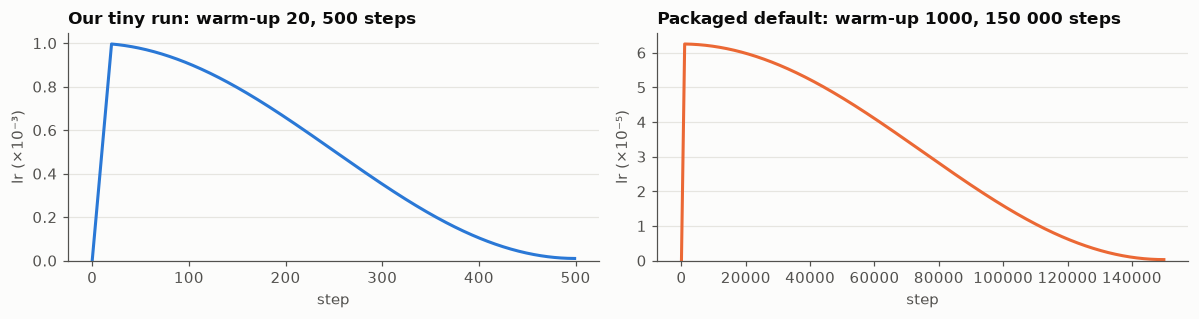

In [15]:
from timm.scheduler import CosineLRScheduler

def lr_curve(lr, warmup, t_initial, lr_min, n):
    opt = torch.optim.AdamW([torch.nn.Parameter(torch.zeros(1))], lr=lr)
    sch = CosineLRScheduler(opt, t_initial=t_initial, lr_min=lr_min, warmup_t=warmup, t_in_epochs=False)
    out = []
    for step in range(n):
        sch.step_update(step)
        out.append(opt.param_groups[0]["lr"])
    return np.array(out)

o = cfg.training.optimization
tiny = lr_curve(o.lr, o.lr_scheduler.warmup_t, cfg.training.max_steps, o.lr_scheduler.lr_min, cfg.training.max_steps)
default = lr_curve(0.625e-4, 1000, 150000, 3e-7, 150000)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3))
a1.plot(tiny * 1e3, color=SERIES[0], lw=2)
a1.set_title(f"Our tiny run: warm-up {o.lr_scheduler.warmup_t}, {cfg.training.max_steps} steps")
a1.set_ylabel("lr (×10⁻³)"); a1.set_xlabel("step")
a2.plot(np.arange(0, 150000, 50), default[::50] * 1e5, color=SERIES[1], lw=2)
a2.set_title("Packaged default: warm-up 1000, 150 000 steps"); a2.set_ylabel("lr (×10⁻⁵)"); a2.set_xlabel("step")
for a in (a1, a2):
    a.set_ylim(0, None); a.grid(axis="y", color=GRID, lw=0.8)
fig.tight_layout(); plt.show()

**Rollout** (`task.rollout`). With rollout *R* the model is applied autoregressively *R* times inside one training
step (its own prediction becomes the next input, see the timeline figure) and the losses are averaged. This trains
the model for what it does in a forecast: step on its own output, so errors that grow over many steps are penalised.
It costs memory and time roughly linearly in *R*. The usual recipe is to pre-train with `rollout.start: 1`
and fine-tune with an increasing rollout (`epoch_increment: 1`, `maximum: 12`). `validation_rollout` lets you
validate on longer forecasts than you train on.

**Checkpoints** (`diagnostics.checkpoint`, written to `system.output.root/checkpoint/<run_id>/`). Every save writes
**two** files:

| file | contents | used for |
|------|----------|----------|
| `last.ckpt`, `anemoi-by_epoch-…ckpt` | Lightning checkpoint: weights + optimiser + scheduler + data-loader state | resuming (`training.run_id`) or forking (`training.fork_run_id`, `system.input.warm_start`) a training run |
| `inference-last.ckpt`, `inference-anemoi-…ckpt` | the pickled model only, plus a JSON **metadata** record (config, dataset description, variable indices, input/output time steps, provenance) and supporting arrays (lat/lon) | `anemoi-inference`: everything needed to run a forecast without the training config |

The inference checkpoint is self-describing: inference reads the variables, grid and time steps from the metadata
instead of trusting the user to match them.

**Logging** (`diagnostics.log`). This version ships MLflow (`AnemoiMLflowLogger`) and Weights & Biases loggers; both
are off by default (no TensorBoard or CSV logger is configured, although Lightning has them). Compute nodes have no
internet, so we use **MLflow in offline mode**: metrics go to plain files in `system.output.root/logs/mlflow`, which
you can read directly (we do below) or sync to a server later with `anemoi-training mlflow sync`.

**Hardware and Slurm** (`system.hardware`). Lightning gets `devices = num_gpus_per_node` and `num_nodes`, and
uses the Slurm environment when it is launched with `srun`, one task per GPU:

| Slurm (`#SBATCH`) | config | meaning |
|-------------------|--------|---------|
| `--nodes=N` | `system.hardware.num_nodes=N` | nodes |
| `--ntasks-per-node=G`, `--gres=gpu:G` | `system.hardware.num_gpus_per_node=G` | one process per GPU |
| | `system.hardware.num_gpus_per_model=M` | GPUs that share one model copy (sharding); N·G/M data-parallel copies |
| `--cpus-per-task=C` | `dataloader.num_workers.*` | data-loading processes per GPU (keep their sum ≤ C) |

The packaged `system: slurm` option reads `SLURM_GPUS_PER_NODE` and `SLURM_NNODES` from the environment.
On Leonardo a Booster node has 4 × A100 64 GB and 32 cores. See `scripts/train_tiny.sbatch` for a 1-GPU job.

## 5 · A few training steps on the CPU (≈ 1 min)

`trainer.train()` creates the Lightning `Trainer` and calls `fit`. We run 12 optimiser steps with the 2.3 M
parameter model. This is only to watch the machinery and the loss printout; real training runs on a GPU.

In [16]:
for name in ["anemoi", "pytorch_lightning", "lightning_fabric", "lightning.pytorch"]:
    logging.getLogger(name).setLevel(logging.WARNING)
t = time.time()
trainer.train()
print(f"\n12 training steps + checkpoint on the CPU: {time.time() - t:.0f} s")

┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type                 ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model   │ AnemoiModelInterface │  2.3 M │ train │     0 │
│ 1 │ loss    │ ModuleDict           │      0 │ train │     0 │
│ 2 │ metrics │ ModuleDict           │      0 │ train │     0 │
└───┴─────────┴──────────────────────┴────────┴───────┴───────┘

Trainable params: 2.3 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 2.3 M                                                                                                
Total estimated model params size (MB): 9.089                                                                      
Modules in train mode: 210                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Training: |          | 0/? [00:00<?, ?it/s]

Checkpoint does not contain variables_metadata. Skipping unit compatibility check.


Training: |          | 0/? [00:00<?, ?it/s]

...

Epoch 0: 100%|██████████| 12/12 [00:32<00:00,  0.37it/s, v_num=448f, train_multi_dataset_loss_step=0.0593]

Epoch 0: 100%|██████████| 12/12 [00:32<00:00,  0.37it/s, v_num=448f, train_multi_dataset_loss_step=0.0554]

Epoch 0: 100%|██████████| 12/12 [00:32<00:00,  0.37it/s, v_num=448f, train_multi_dataset_loss_step=0.0554, train_multi_dataset_loss_epoch=0.0629]

Epoch 0: 100%|██████████| 12/12 [00:32<00:00,  0.36it/s, v_num=448f, train_multi_dataset_loss_step=0.0554, train_multi_dataset_loss_epoch=0.0629]


12 training steps + checkpoint on the CPU: 59 s


metrics logged: ['epoch', 'lr-AdamW', 'rollout', 'train_multi_dataset_loss_epoch', 'train_multi_dataset_loss_step']


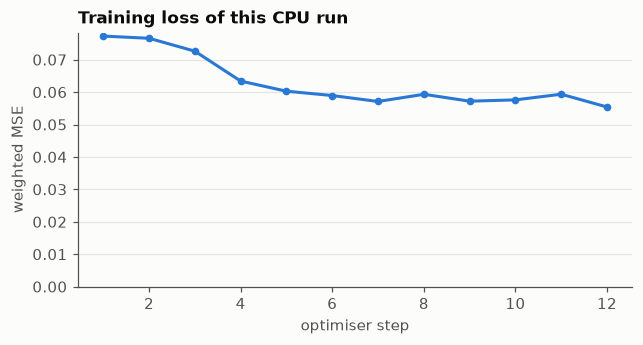

loss: step 1 = 0.0773  ->  step 12 = 0.0554


In [17]:
def read_metric(run_dir, name):
    a = np.loadtxt(run_dir / "metrics" / name, ndmin=2)        # MLflow file store: "timestamp value step"
    a = a[np.argsort(a[:, 2])]
    return a[:, 2] + 1, a[:, 1]

run_dir = next((OUT / "logs" / "mlflow").glob(f"*/{trainer.run_id}"))
print("metrics logged:", sorted(p.name for p in (run_dir / "metrics").iterdir()))
steps, loss = read_metric(run_dir, "train_multi_dataset_loss_step")
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(steps, loss, marker="o", ms=4, lw=2, color=SERIES[0])
ax.set_xlabel("optimiser step"); ax.set_ylabel("weighted MSE")
ax.set_title("Training loss of this CPU run"); ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_ylim(0, None)
plt.show()
print(f"loss: step 1 = {loss[0]:.4f}  ->  step {int(steps[-1])} = {loss[-1]:.4f}")

And the checkpoint directory. The inference checkpoint carries its metadata as JSON inside the file:

In [18]:
from anemoi.utils.checkpoints import load_metadata

ckpt_dir = Path(trainer.config.system.output.checkpoints.root)
for p in sorted(ckpt_dir.iterdir()):
    print(f"  {p.name:<52} {p.stat().st_size / 1e6:6.1f} MB")

meta = load_metadata(str(ckpt_dir / "inference-last.ckpt"))
inf = meta["metadata_inference"]["data"]
print("\nmetadata keys:", sorted(meta))
print("timesteps:", {k: inf["timesteps"][k] for k in ("timestep", "input_relative_date_indices", "output_relative_date_indices")})
print("forcing variables:", inf["variable_types"]["forcing"][:5], "...")
proc = meta["config"]["model"]["processor"]
print("training config inside: processor", proc["_target_"].split(".")[-1], "with", proc["num_layers"], "layers,",
      proc["num_channels"], "channels; task multistep_input =", meta["config"]["task"]["multistep_input"])

  anemoi-by_epoch-epoch_000-step_000012.ckpt             34.6 MB
  inference-anemoi-by_epoch-epoch_000-step_000012.ckpt   21.1 MB
  inference-last.ckpt                                    21.1 MB
  last.ckpt                                              34.6 MB

metadata keys: ['base_seed', 'config', 'data_indices', 'dataset', 'metadata_inference', 'model', 'provenance_training', 'run_id', 'seed', 'supporting_arrays_paths', 'task', 'timestamp', 'tracker', 'training', 'uuid', 'version']
timesteps: {'timestep': '6h', 'input_relative_date_indices': [0, 1], 'output_relative_date_indices': [2]}
forcing variables: ['cos_julian_day', 'cos_latitude', 'cos_local_time', 'cos_longitude', 'insolation'] ...
training config inside: processor GNNProcessor with 4 layers, 64 channels; task multistep_input = 2


### What the same config does on a GPU

`scripts/train_tiny.sbatch` runs `configs/04_tiny_train.yaml` unchanged on one A100 (500 steps, about 17 epochs
of the 29 training samples). Reference run (job 62108028, `boost_qos_dbg`, 8 cores):

![Reference GPU run](figures/04_gpu_reference_loss.svg)

| | |
|---|---|
| job wall time | 5 min 35 s (≈ 0.75 core-hours with 8 cores) |
| of which: Python imports + config + graph + model setup | ≈ 4 min (imports from Lustre dominate) |
| of which: 500 training steps + 17 validations + checkpoints | ≈ 65 s (≈ 9 steps/s) |
| peak GPU memory | 2.5 GB of 64 GB |
| training loss (first → last logged) | 0.059 → 0.031 |
| validation loss (epoch 1 → 17) | 0.057 → 0.037 |

A second reference run passed four overrides to the same script
(`sbatch scripts/train_tiny.sbatch model.num_channels=256 model.processor.num_layers=8 task.rollout.start=2 task.rollout.maximum=2`):
8.8 M parameters, rollout 2, about 6.5 steps/s, 4.1 GB of GPU memory, a 6.5 min job, and a training loss of
0.096 → 0.040 (averaged over the two rollout steps, so not directly comparable with the run above).
Startup took about as long as in the first run: on these short jobs, **startup costs more than training**.

The training loss keeps falling while the validation loss flattens: with only 29 training samples the model starts
to memorise them. That is fine for a demonstration and is exactly the trade-off (data, model size, steps)
you will play with in the second hour.

## 6 · Try it

Both exercises only compose configs, so they run in seconds.

**Exercise 1: rollout.** Compose the tiny config with a training rollout of 3 steps (fixed, not growing).
How many dates does one training sample contain now, and how many training samples are there?
*Hint:* overrides go in `compose_cfg([...])`; the datamodule is `AnemoiDatasetsDataModule(config, task)`.

In [19]:
# Your code here

<details>
<summary><b>Solution</b> (click to expand)</summary>

```python
from anemoi.training.data.datamodule import AnemoiDatasetsDataModule
from anemoi.training.schemas.base_schema import convert_to_omegaconf
from hydra.utils import instantiate

c = compose_cfg(["task.rollout.start=3", "task.rollout.maximum=3"])
vc = convert_to_omegaconf(validate(c))            # what AnemoiTrainer does internally
task3 = instantiate(vc.task)
dm3 = AnemoiDatasetsDataModule(vc, task3)
print([f"{o.total_seconds() / 3600:+.0f}h" for o in task3.get_offsets(mode="training")])  # -6h .. +18h
print(dm3.ds_train.get_sample(0)["data"].shape)                  # 5 dates
print(len(dm3.ds_train.anchors))                                 # 27 = 29 - 2
```

Five dates (2 inputs + 3 targets), and two fewer samples, because every sample now needs 18 h of future data.
On the command line it is the same override:
`anemoi-training train --config-path $PWD/configs --config-name 04_tiny_train task.rollout.start=3 task.rollout.maximum=3`.
To *grow* the rollout during training use `task.rollout.start=1 task.rollout.epoch_increment=1 task.rollout.maximum=3`.
</details>

**Exercise 2: four GPUs.** You move the tiny run to a full Booster node (4 GPUs). Write the overrides and the
`#SBATCH` lines that change, and work out the effective batch size and the effective learning rate. Check your
answer with `validate(...)` and the formula of §4.

In [20]:
# Your code here

<details>
<summary><b>Solution</b> (click to expand)</summary>

```bash
#SBATCH --nodes=1
#SBATCH --ntasks-per-node=4
#SBATCH --gres=gpu:4
#SBATCH --cpus-per-task=8
srun anemoi-training train --config-path $PWD/configs --config-name 04_tiny_train system.hardware.num_gpus_per_node=4
```

```python
c4 = compose_cfg(["system.hardware.num_gpus_per_node=4"])
h = validate(c4).system.hardware
copies = h.num_nodes * h.num_gpus_per_node / h.num_gpus_per_model
print("effective batch:", c4.dataloader.batch_size.training * copies)          # 1 x 4 = 4
print("effective lr:", c4.training.optimization.lr * copies)                    # 1e-3 x 4 = 4e-3
```

Four data-parallel copies: effective batch size 4 and effective learning rate 4 × 10⁻³. With only 29 training
samples an epoch is now 8 steps, so to see the same number of samples per GPU you would also divide `max_steps`
by 4 (`t_initial` of the scheduler follows `max_steps`). Keeping the old per-step behaviour instead means
`training.optimization.lr=2.5e-4`.
</details>

## Summary: from this notebook to your own training run

- One composed config drives everything: `defaults:` picks one option per group, your YAML overrides values, and the
  command line overrides those. Validate before you submit (`anemoi-training config validate`).
- `dataloader.*.datasets.data.dataset_config` goes straight to `open_dataset`: dates, variables (`select`/`drop`)
  and sub-areas are dataset decisions.
- One sample = `multistep_input` input dates + `rollout` target dates; the loss is an MSE weighted by **area**
  (graph node weights) and by **variable** (scalers), and those weights express your priorities.
- The effective learning rate scales with the number of GPUs; checkpoints come in pairs (resume vs inference with
  metadata); logs stay offline on Leonardo.

The natural knobs for the second hour:

| decision | where |
|----------|-------|
| dataset, dates for train/validation | `system.input.dataset`, `dataloader.{training,validation}.datasets.data.{start,end}` |
| variables | `dataset_config.select` / `drop`, and `data.forcing` / `data.diagnostic` to match |
| what matters in the loss | `training.scalers.datasets.data.general_variable.weights`, `training.training_loss` |
| model size | `model.num_channels`, `model.processor.num_layers`, `graph.nodes.hidden.node_builder.resolution` |
| temporal setup | `task.multistep_input`, `task.timestep`, `task.rollout` |
| optimisation | `training.optimization.lr`, `lr_scheduler.warmup_t`, `training.max_steps`, `dataloader.batch_size` |
| hardware | `system.hardware.*` + matching `#SBATCH` lines |

In [21]:
print(f"Notebook executed in {time.time() - T0:.0f} s")

Notebook executed in 320 s
